# Task 4: Advanced Analytics and Statistical Modeling

This notebook applies descriptive and inferential statistics, time-series analysis, customer segmentation, and predictive modeling. Run it from top to bottom after installing the project requirements.

**Important data boundary:** The Telco churn data is a one-time customer snapshot and has no calendar dates. It cannot support genuine customer time-series forecasting. The forecasting section therefore uses a separate, cited daily temperature sample; its forecasts are not Telco business forecasts.

## 1. Setup and data loading

The Telco analysis uses the cleaned project dataset. For the independent time-series exercise, the notebook prefers a local copy of `data/raw/daily-min-temperatures.csv` and otherwise reads the public source directly. Source: [daily minimum temperatures sample](https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv). An internet connection is needed if no local copy is available.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, f1_score, mean_absolute_error,
    mean_squared_error, precision_score, recall_score, roc_auc_score,
    roc_curve, silhouette_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.holtwinters import SimpleExpSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.proportion import proportion_confint

SEED = 42
ALPHA = 0.05
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 40)

DATASET_NAME = 'telco_churn_clean.csv'
project_root = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / 'data' / 'processed' / DATASET_NAME).is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        'Could not locate data/processed/telco_churn_clean.csv. '
        'Run this notebook from the project or notebooks directory.'
    )

telco_path = project_root / 'data' / 'processed' / DATASET_NAME
telco = pd.read_csv(telco_path)
required_columns = {
    'customer_id', 'tenure', 'monthly_charges', 'total_charges',
    'contract', 'internet_service', 'payment_method', 'churn',
}
missing_columns = required_columns.difference(telco.columns)
if missing_columns:
    raise ValueError(f'Telco dataset is missing required columns: {sorted(missing_columns)}')

print(f'Project root: {project_root}')
print(f'Telco data: {telco.shape[0]:,} rows x {telco.shape[1]} columns')
print(f'Churn rate: {(telco["churn"] == "Yes").mean():.1%}')
display(telco.head())

Project root: C:\Rahul\Apex_Planet
Telco data: 7,043 rows x 21 columns
Churn rate: 26.5%


,customer_id,gender,senior_citizen,partner,dependents,tenure,phone_service,multiple_lines,internet_service,online_security,online_backup,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn
0,7590-VHVEG,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Statistical analysis (Days 28-30)

The summaries describe this sample. Tests use a 5% significance threshold; statistical significance does not establish practical importance or causation.

In [2]:
numeric_columns = telco.select_dtypes(include='number').columns.tolist()
descriptive = telco[numeric_columns].agg(
    ['count', 'mean', 'median', 'var', 'std', 'skew', 'kurt']
).T
descriptive['mode'] = [
    telco[column].mode().iloc[0] if not telco[column].mode().empty else np.nan
    for column in numeric_columns
]
descriptive = descriptive.rename(columns={
    'var': 'variance', 'std': 'standard_deviation',
    'skew': 'skewness', 'kurt': 'kurtosis',
})
display(descriptive.round(3))

categorical_columns = telco.select_dtypes(exclude='number').columns.difference(
    ['customer_id']
).tolist()
categorical_summary = pd.concat([
    telco[column].value_counts(dropna=False).rename('count').to_frame()
    .assign(proportion=telco[column].value_counts(normalize=True, dropna=False))
    .assign(feature=column)
    for column in categorical_columns
]).rename_axis('level').reset_index()
display(categorical_summary[['feature', 'level', 'count', 'proportion']])

,count,mean,median,variance,standard_deviation,skewness,kurtosis,mode
tenure,7043.0,32.371,29.000,603.168,24.559,0.240,-1.387,1.00
monthly_charges,7043.0,64.762,70.350,905.411,30.090,-0.221,-1.257,20.05
total_charges,7043.0,2281.917,1397.475,5131449.978,2265.270,0.964,-0.226,20.20


,feature,level,count,proportion
0,churn,No,5174,0.734630
1,churn,Yes,1869,0.265370
2,contract,Month-to-month,3875,0.550192
3,contract,Two year,1695,0.240664
4,contract,One year,1473,0.209144
5,dependents,No,4933,0.700412
6,dependents,Yes,2110,0.299588
7,device_protection,No,3095,0.439443
8,device_protection,Yes,2422,0.343888
9,device_protection,No internet service,1526,0.216669


In [3]:
churn_flag = telco['churn'].eq('Yes').astype(int)
churn_count = int(churn_flag.sum())
customer_count = int(churn_flag.count())
churn_rate = churn_count / customer_count
ci_low, ci_high = proportion_confint(churn_count, customer_count, alpha=ALPHA, method='wilson')
print(
    f'Churn proportion: {churn_rate:.3%} '
    f'(95% Wilson CI: {ci_low:.3%} to {ci_high:.3%}; '
    f'{churn_count:,} of {customer_count:,} customers)'
)

Churn proportion: 26.537% (95% Wilson CI: 25.519% to 27.581%; 1,869 of 7,043 customers)


In [4]:
monthly_charges_no = telco.loc[telco['churn'].eq('No'), 'monthly_charges']
monthly_charges_yes = telco.loc[telco['churn'].eq('Yes'), 'monthly_charges']
welch_test = stats.ttest_ind(monthly_charges_yes, monthly_charges_no, equal_var=False)

contract_table = pd.crosstab(telco['contract'], telco['churn'])
chi2_stat, chi2_p, chi2_dof, chi2_expected = stats.chi2_contingency(contract_table)

contract_groups = [group['monthly_charges'].to_numpy()
                   for _, group in telco.groupby('contract', observed=True)]
anova_test = stats.f_oneway(*contract_groups)

test_results = pd.DataFrame([
    {
        'test': 'Welch t-test: monthly charges by churn',
        'statistic': welch_test.statistic,
        'p_value': welch_test.pvalue,
        'interpretation': 'Evidence of a difference in sample means' if welch_test.pvalue < ALPHA else 'Insufficient evidence of a difference in means',
    },
    {
        'test': 'Chi-square: contract vs churn',
        'statistic': chi2_stat,
        'p_value': chi2_p,
        'interpretation': 'Evidence of an association' if chi2_p < ALPHA else 'Insufficient evidence of an association',
    },
    {
        'test': 'One-way ANOVA: monthly charges by contract',
        'statistic': anova_test.statistic,
        'p_value': anova_test.pvalue,
        'interpretation': 'Evidence that at least one group mean differs' if anova_test.pvalue < ALPHA else 'Insufficient evidence of a group-mean difference',
    },
])
test_results['significant_at_0_05'] = test_results['p_value'] < ALPHA
test_report = test_results.copy()
test_report['statistic'] = test_report['statistic'].map(lambda value: f'{value:.4f}')
test_report['p_value'] = test_report['p_value'].map(lambda value: f'{value:.3e}')
display(test_report)
print(f'Chi-square degrees of freedom: {chi2_dof}; all expected counts >= 5: {(chi2_expected >= 5).all()}')

contract_churn_rates = telco.assign(churn_flag=telco['churn'].eq('Yes')).groupby('contract', observed=True)['churn_flag'].mean()
highest_churn_contract = contract_churn_rates.idxmax()
charge_difference = monthly_charges_yes.mean() - monthly_charges_no.mean()
print(f'Observed churn is {churn_rate:.1%}; the highest contract-level rate is {highest_churn_contract} ({contract_churn_rates.max():.1%}).')
print(f'Churned customers average ${charge_difference:.2f} more per month in this sample (Welch p={welch_test.pvalue:.3e}).')
print('Business implication: consider testing early-tenure support and contract education with measured retention outcomes; these observational patterns are not proof of causes.')
print('Tests use alpha=0.05; very small p-values are shown in scientific notation and do not measure business effect size.')
print('Tests are observational; the results do not show that contract or charges cause churn.')

,test,statistic,p_value,interpretation,significant_at_0_05
0,Welch t-test: monthly charges by churn,18.4075,8.592e-73,Evidence of a difference in sample means,True
1,Chi-square: contract vs churn,1184.5966,5.863e-258,Evidence of an association,True
2,One-way ANOVA: monthly charges by contract,20.8280,9.575e-10,Evidence that at least one group mean differs,True


Chi-square degrees of freedom: 2; all expected counts >= 5: True
Observed churn is 26.5%; the highest contract-level rate is Month-to-month (42.7%).
Churned customers average $13.18 more per month in this sample (Welch p=8.592e-73).
Business implication: consider testing early-tenure support and contract education with measured retention outcomes; these observational patterns are not proof of causes.
Tests use alpha=0.05; very small p-values are shown in scientific notation and do not measure business effect size.
Tests are observational; the results do not show that contract or charges cause churn.


,tenure,monthly_charges,total_charges,churn_flag
tenure,1.000,0.248,0.825,-0.352
monthly_charges,0.248,1.000,0.651,0.193
total_charges,0.825,0.651,1.000,-0.199
churn_flag,-0.352,0.193,-0.199,1.000


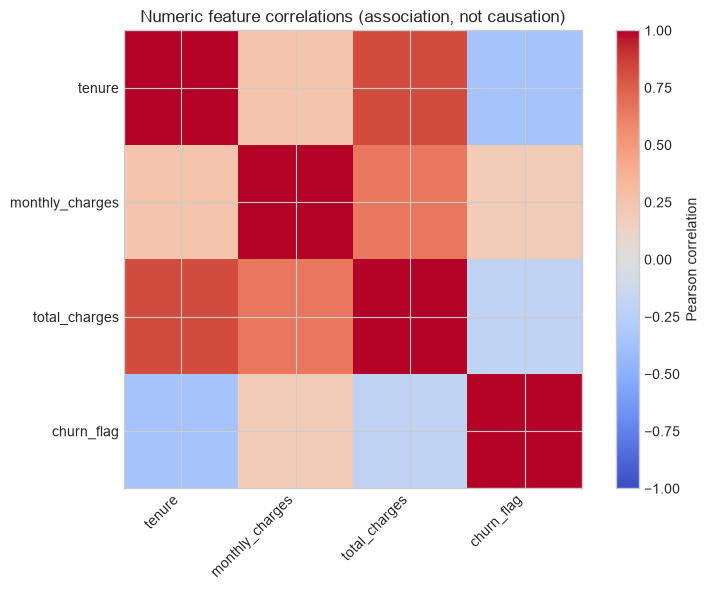

Business interpretation: correlations can prioritize questions for follow-up, but confounding, selection, and the cross-sectional design prevent causal conclusions.


In [5]:
correlation_data = telco[numeric_columns].copy()
correlation_data['churn_flag'] = churn_flag
correlations = correlation_data.corr(method='pearson')
display(correlations.round(3))

plt.figure(figsize=(8, 6))
plt.imshow(correlations, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Pearson correlation')
plt.xticks(range(len(correlations.columns)), correlations.columns, rotation=45, ha='right')
plt.yticks(range(len(correlations.index)), correlations.index)
plt.title('Numeric feature correlations (association, not causation)')
plt.tight_layout()
plt.show()

print('Business interpretation: correlations can prioritize questions for follow-up, but confounding, selection, and the cross-sectional design prevent causal conclusions.')

## 3. Time-series analysis (Days 31-33)

The separate public sample contains daily minimum temperatures in Melbourne, Australia, from 1981 onward. Resampling and forecasts in this section apply only to that series. The monthly series is used for model comparison because it keeps a full annual seasonal cycle while making model fitting quick and interpretable.

In [6]:
temperature_url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv'
temperature_path = project_root / 'data' / 'raw' / 'daily-min-temperatures.csv'
temperature_source = temperature_path if temperature_path.is_file() else temperature_url
temperatures = pd.read_csv(temperature_source, parse_dates=['Date'])
if not {'Date', 'Temp'}.issubset(temperatures.columns):
    raise ValueError('Temperature data must contain Date and Temp columns.')
temperature_series = temperatures.set_index('Date')['Temp'].astype(float).sort_index().asfreq('D')
missing_days = int(temperature_series.isna().sum())
if missing_days:
    missing_dates = temperature_series.index[temperature_series.isna()]
    print(f'Interpolating {missing_days} missing calendar observations: {list(missing_dates.date)}')
    temperature_series = temperature_series.interpolate(method='time', limit_area='inside')
if temperature_series.isna().any():
    raise ValueError('Temperature series contains unfilled gaps; inspect the source before analysis.')
print(f'Source: {temperature_source}')
print(f'Observations: {len(temperature_series):,}; range: {temperature_series.index.min().date()} to {temperature_series.index.max().date()}')
print(f'Missing calendar days found and interpolated: {missing_days}; remaining gaps: {int(temperature_series.isna().sum())}')
display(temperature_series.head().to_frame('daily_min_temp'))

Interpolating 2 missing calendar observations: [datetime.date(1984, 12, 31), datetime.date(1988, 12, 31)]
Source: C:\Rahul\Apex_Planet\data\raw\daily-min-temperatures.csv
Observations: 3,652; range: 1981-01-01 to 1990-12-31
Missing calendar days found and interpolated: 2; remaining gaps: 0


,daily_min_temp
Date,
1981-01-01,20.7
1981-01-02,17.9
1981-01-03,18.8
1981-01-04,14.6
1981-01-05,15.8


,frequency,observations,mean_temperature
0,daily,3652,11.18
1,weekly (week ending Sunday),523,11.19
2,monthly,120,11.20


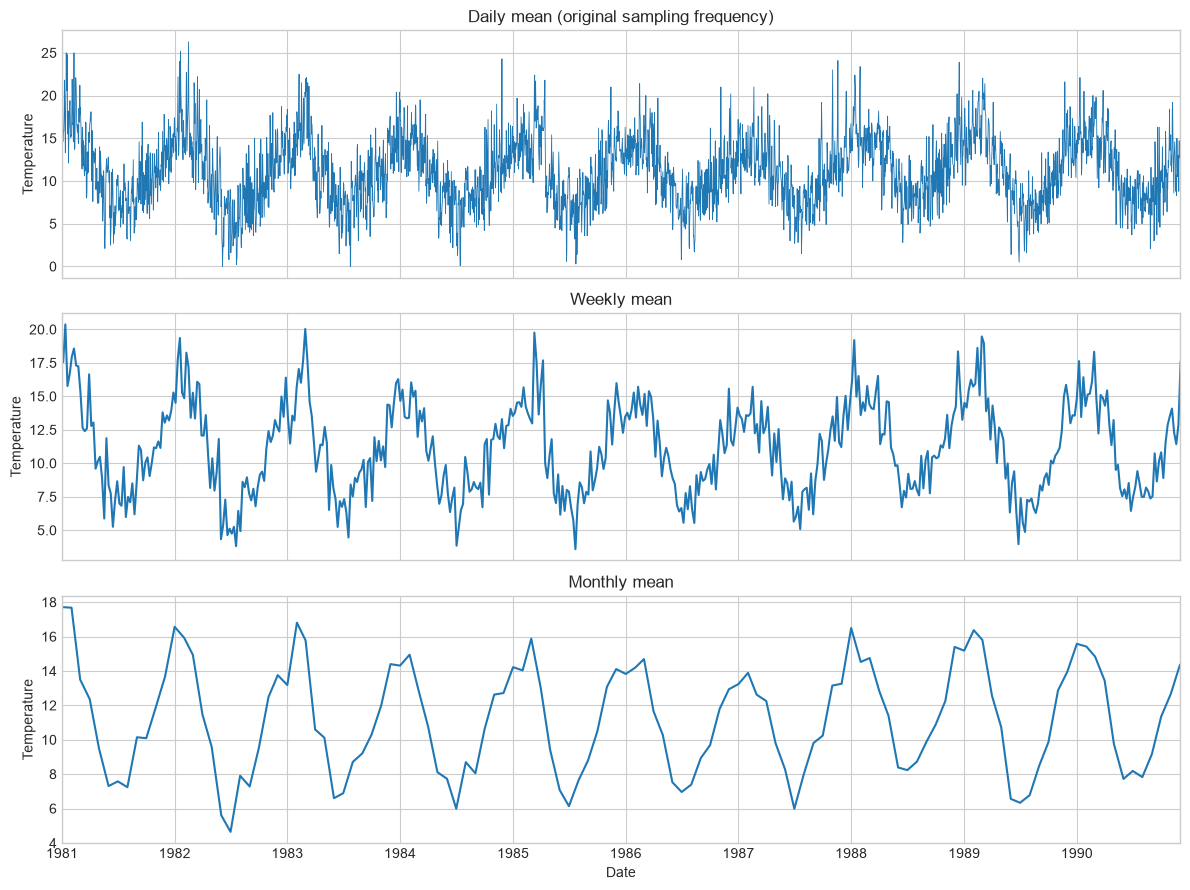

In [7]:
daily_mean = temperature_series.resample('D').mean()
weekly_mean = temperature_series.resample('W-SUN').mean()
monthly_mean = temperature_series.resample('ME').mean()
resampling_summary = pd.DataFrame({
    'frequency': ['daily', 'weekly (week ending Sunday)', 'monthly'],
    'observations': [len(daily_mean), len(weekly_mean), len(monthly_mean)],
    'mean_temperature': [daily_mean.mean(), weekly_mean.mean(), monthly_mean.mean()],
})
display(resampling_summary.round(2))

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
daily_mean.plot(ax=axes[0], title='Daily mean (original sampling frequency)', linewidth=0.6)
weekly_mean.plot(ax=axes[1], title='Weekly mean')
monthly_mean.plot(ax=axes[2], title='Monthly mean')
for axis in axes:
    axis.set_ylabel('Temperature')
plt.tight_layout()
plt.show()

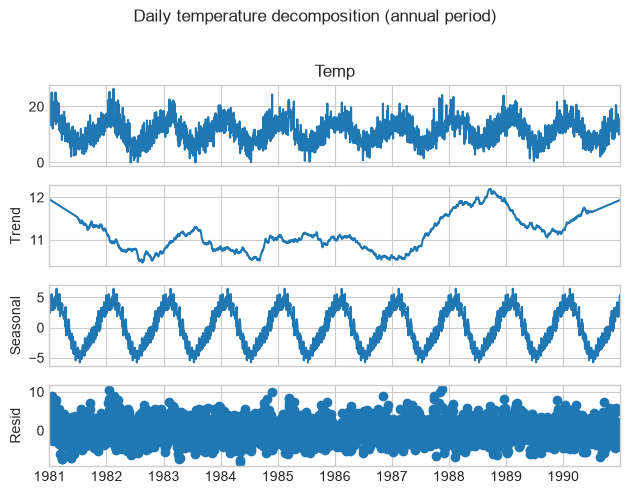

ADF statistic: -4.4411; p-value: 0.000250907; lags: 20; observations: 3631
5% critical value: -2.8623
At alpha=0.05, reject the unit-root null.
The ADF result is evidence about stationarity, not proof that all time-series assumptions hold.


In [8]:
daily_decomposition = seasonal_decompose(
    temperature_series, model='additive', period=365, extrapolate_trend='period'
)
daily_decomposition.plot()
plt.suptitle('Daily temperature decomposition (annual period)', y=1.02)
plt.tight_layout()
plt.show()

adf_result = adfuller(temperature_series, autolag='AIC', result_object=True)
print(f'ADF statistic: {adf_result.statistic:.4f}; p-value: {adf_result.pvalue:.6g}; lags: {adf_result.lags}; observations: {adf_result.nobs}')
print(f'5% critical value: {adf_result.critical_values["5%"]:.4f}')
print('At alpha=0.05, reject the unit-root null.' if adf_result.pvalue < ALPHA else 'At alpha=0.05, do not reject the unit-root null.')
print('The ADF result is evidence about stationarity, not proof that all time-series assumptions hold.')

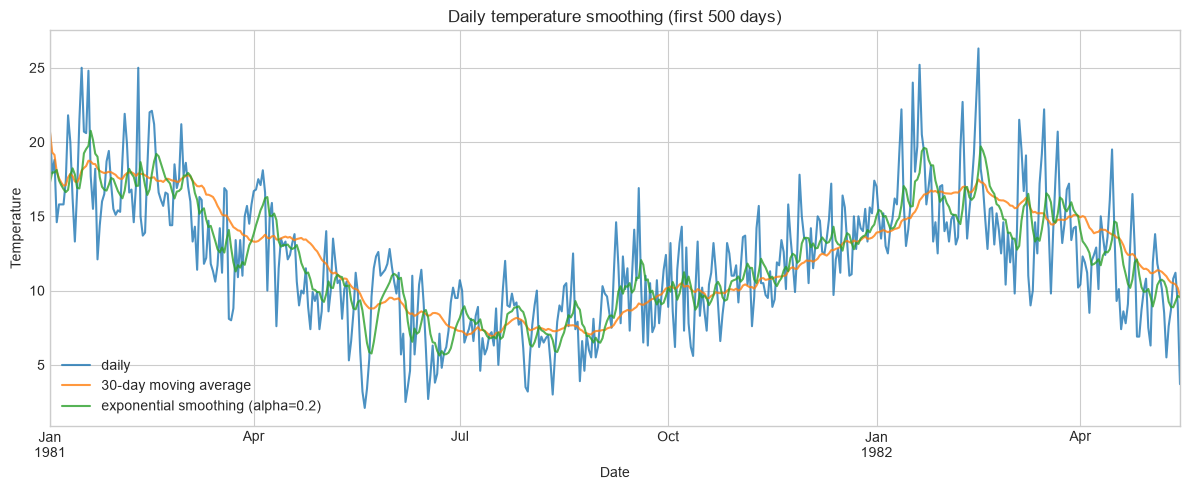

In [9]:
moving_average_30d = temperature_series.rolling(window=30, min_periods=1).mean()
exp_smoothing_fit = SimpleExpSmoothing(
    temperature_series, initialization_method='estimated'
).fit(smoothing_level=0.2, optimized=False)
smoothed = pd.DataFrame({
    'daily': temperature_series,
    '30-day moving average': moving_average_30d,
    'exponential smoothing (alpha=0.2)': exp_smoothing_fit.fittedvalues,
})
smoothed.iloc[:500].plot(figsize=(12, 5), alpha=0.8)
plt.title('Daily temperature smoothing (first 500 days)')
plt.ylabel('Temperature')
plt.tight_layout()
plt.show()

,MAE,RMSE,MAPE_percent
"ARIMA(2,1,2)",0.817,1.070,8.165
"SARIMA(1,1,1)x(1,1,1,12)",0.468,0.616,4.265


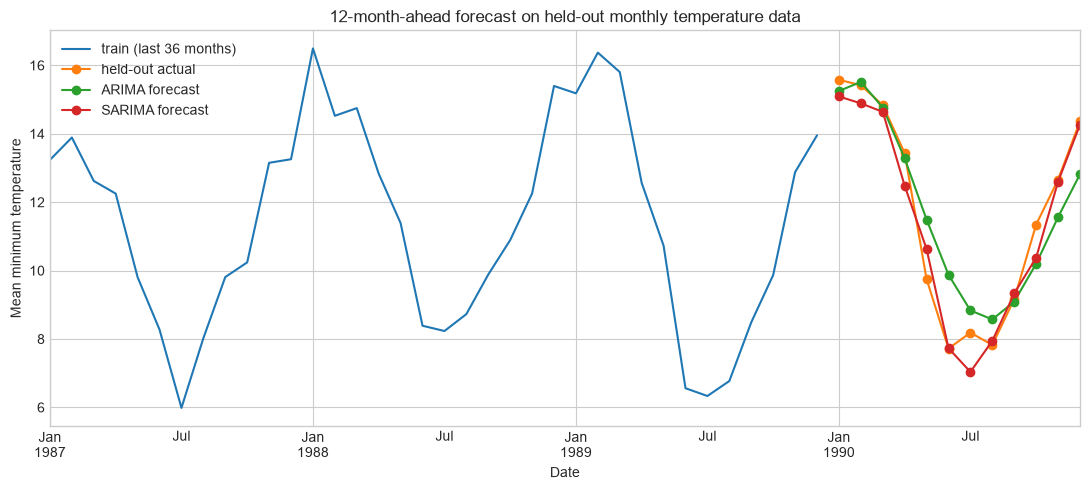

These are held-out weather-sample errors, not customer churn or telecom sales forecast accuracy.


In [10]:
forecast_series = monthly_mean.copy()
forecast_series.index = forecast_series.index.to_period('M')
forecast_horizon = 12
train_series = forecast_series.iloc[:-forecast_horizon]
test_series = forecast_series.iloc[-forecast_horizon:]

arima_fit = SARIMAX(
    train_series, order=(2, 1, 2), trend='n',
    enforce_stationarity=False, enforce_invertibility=False,
).fit(disp=False)
sarima_fit = SARIMAX(
    train_series, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12), trend='n',
    enforce_stationarity=False, enforce_invertibility=False,
).fit(disp=False)

arima_forecast = arima_fit.get_forecast(steps=forecast_horizon).predicted_mean
sarima_forecast = sarima_fit.get_forecast(steps=forecast_horizon).predicted_mean

def forecast_metrics(actual, predicted):
    actual_values = np.asarray(actual, dtype=float)
    predicted_values = np.asarray(predicted, dtype=float)
    nonzero = actual_values != 0
    mape = np.mean(np.abs((actual_values[nonzero] - predicted_values[nonzero]) / actual_values[nonzero])) * 100
    return {
        'MAE': mean_absolute_error(actual_values, predicted_values),
        'RMSE': np.sqrt(mean_squared_error(actual_values, predicted_values)),
        'MAPE_percent': mape,
    }

forecast_results = pd.DataFrame({
    'ARIMA(2,1,2)': forecast_metrics(test_series, arima_forecast),
    'SARIMA(1,1,1)x(1,1,1,12)': forecast_metrics(test_series, sarima_forecast),
}).T
display(forecast_results.round(3))

plt.figure(figsize=(11, 5))
train_series.tail(36).plot(label='train (last 36 months)')
test_series.plot(label='held-out actual', marker='o')
arima_forecast.plot(label='ARIMA forecast', marker='o')
sarima_forecast.plot(label='SARIMA forecast', marker='o')
plt.title('12-month-ahead forecast on held-out monthly temperature data')
plt.ylabel('Mean minimum temperature')
plt.legend()
plt.tight_layout()
plt.show()
print('These are held-out weather-sample errors, not customer churn or telecom sales forecast accuracy.')

## 4. Customer segmentation with clustering (Days 34-36)

Customer identifiers and churn outcomes are excluded from clustering inputs to avoid treating an ID or the target outcome as a segmentation feature. Numeric features are standardized and categorical features are one-hot encoded. The silhouette score is used alongside inertia; it is a heuristic rather than proof of a uniquely correct number of segments.

,inertia,silhouette
k,,
2,22789.326,0.319
3,17407.696,0.305
4,14625.342,0.304
5,12668.354,0.299
6,11117.844,0.314
7,10145.521,0.299
8,9352.556,0.302


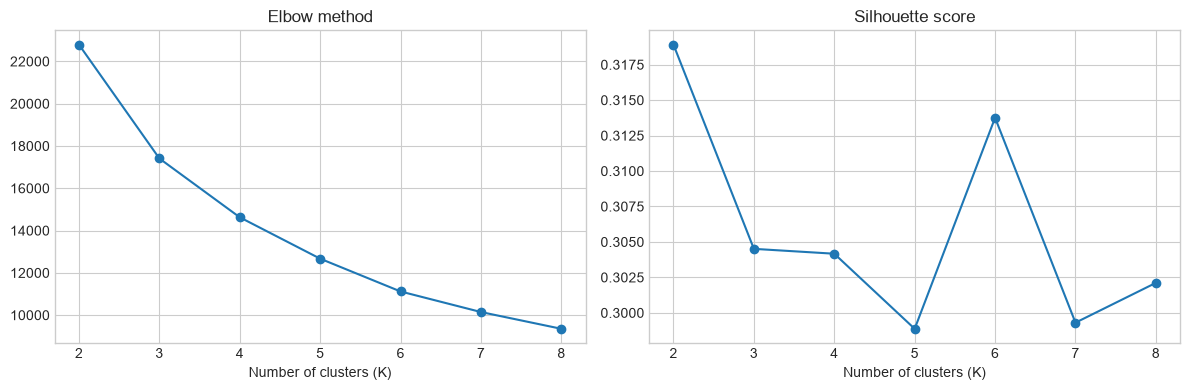

Selected K=2 by the highest silhouette score in the tested range.


In [11]:
cluster_numeric = ['tenure', 'monthly_charges', 'total_charges']
cluster_categorical = ['contract', 'internet_service', 'payment_method']
cluster_features = telco[cluster_numeric + cluster_categorical].copy()
cluster_preprocessor = ColumnTransformer([
    ('numeric', StandardScaler(), cluster_numeric),
    ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cluster_categorical),
], verbose_feature_names_out=False)
cluster_matrix = cluster_preprocessor.fit_transform(cluster_features)

candidate_ks = range(2, 9)
cluster_scores = []
for k in candidate_ks:
    candidate_model = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    candidate_labels = candidate_model.fit_predict(cluster_matrix)
    cluster_scores.append({
        'k': k,
        'inertia': candidate_model.inertia_,
        'silhouette': silhouette_score(cluster_matrix, candidate_labels),
    })
cluster_scores = pd.DataFrame(cluster_scores).set_index('k')
display(cluster_scores.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cluster_scores['inertia'].plot(marker='o', ax=axes[0], title='Elbow method')
cluster_scores['silhouette'].plot(marker='o', ax=axes[1], title='Silhouette score')
axes[0].set_xlabel('Number of clusters (K)')
axes[1].set_xlabel('Number of clusters (K)')
plt.tight_layout()
plt.show()

best_k = int(cluster_scores['silhouette'].idxmax())
kmeans = KMeans(n_clusters=best_k, random_state=SEED, n_init=10)
telco['segment'] = kmeans.fit_predict(cluster_matrix)
telco['churn_flag'] = telco['churn'].eq('Yes').astype(int)
print(f'Selected K={best_k} by the highest silhouette score in the tested range.')

,customer_count,mean_tenure,mean_monthly_charges,mean_total_charges,churn_rate,female_share,senior_share,partner_share,dependents_share,common_contract,common_internet_service,common_payment_method,customer_share
segment,,,,,,,,,,,,,
0,2384,56.697,89.516,5058.488,0.167,0.494,0.214,0.666,0.333,Two year,Fiber optic,Bank transfer (automatic),0.338
1,4659,19.924,52.095,861.152,0.316,0.496,0.136,0.389,0.283,Month-to-month,DSL,Electronic check,0.662


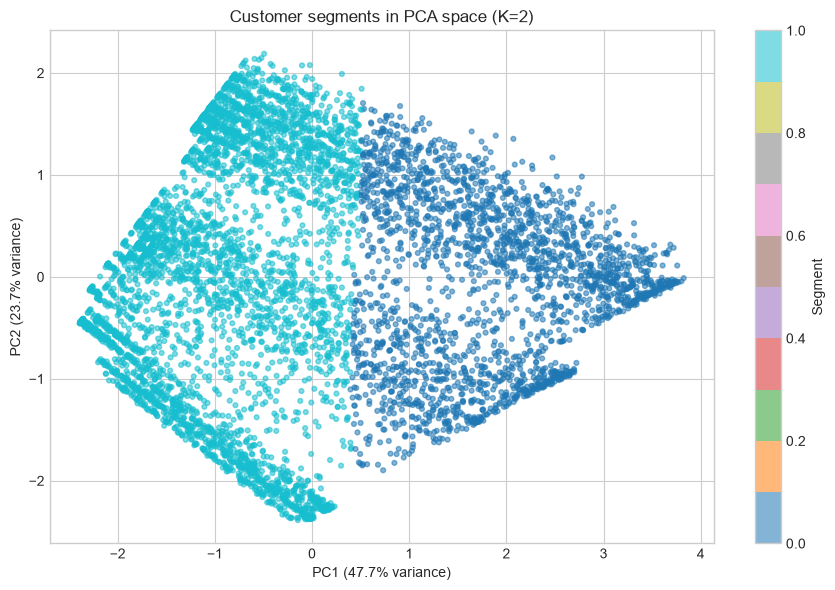

Segment 0: Explore loyalty recognition and monitor service satisfaction.
Segment 1: Review retention support for this profile; validate any offer with a controlled test.
Recommendations are hypotheses based on segment profiles, not evidence that an intervention will cause retention.


In [12]:
segment_profile = telco.groupby('segment', observed=True).agg(
    customer_count=('customer_id', 'size'),
    mean_tenure=('tenure', 'mean'),
    mean_monthly_charges=('monthly_charges', 'mean'),
    mean_total_charges=('total_charges', 'mean'),
    churn_rate=('churn_flag', 'mean'),
    female_share=('gender', lambda values: values.eq('Female').mean()),
    senior_share=('senior_citizen', lambda values: values.eq('Yes').mean()),
    partner_share=('partner', lambda values: values.eq('Yes').mean()),
    dependents_share=('dependents', lambda values: values.eq('Yes').mean()),
    common_contract=('contract', lambda values: values.mode().iloc[0]),
    common_internet_service=('internet_service', lambda values: values.mode().iloc[0]),
    common_payment_method=('payment_method', lambda values: values.mode().iloc[0]),
)
segment_profile['customer_share'] = segment_profile['customer_count'] / len(telco)
display(segment_profile.round(3))

pca = PCA(n_components=2, random_state=SEED)
cluster_coordinates = pca.fit_transform(cluster_matrix)
plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    cluster_coordinates[:, 0], cluster_coordinates[:, 1],
    c=telco['segment'], cmap='tab10', s=12, alpha=0.55,
)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)')
plt.title(f'Customer segments in PCA space (K={best_k})')
plt.colorbar(scatter, label='Segment')
plt.tight_layout()
plt.show()

overall_churn_rate = telco['churn_flag'].mean()
for segment_id, profile in segment_profile.iterrows():
    if profile['churn_rate'] > overall_churn_rate:
        recommendation = 'Review retention support for this profile; validate any offer with a controlled test.'
    elif profile['mean_tenure'] < telco['tenure'].median():
        recommendation = 'Consider onboarding education and monitor early-life retention.'
    else:
        recommendation = 'Explore loyalty recognition and monitor service satisfaction.'
    print(f'Segment {segment_id}: {recommendation}')
print('Recommendations are hypotheses based on segment profiles, not evidence that an intervention will cause retention.')

## 5. Predictive modeling (Days 37-38)

Churn classification compares class-weighted logistic regression and a shallow decision tree. A stratified holdout preserves the observed class proportions. Preprocessing is fit inside each pipeline on training data only. `total_charges` is excluded because it overlaps strongly with tenure and may encode information accumulated over the same period as the churn outcome. The reported recall and other scores are measured on this single holdout and should not be interpreted as guaranteed production performance.

In [13]:
classification_target = telco['churn'].eq('Yes').astype(int)
classification_features = telco.drop(columns=['customer_id', 'churn', 'total_charges', 'segment', 'churn_flag'], errors='ignore')
classification_numeric = classification_features.select_dtypes(include='number').columns.tolist()
classification_categorical = classification_features.select_dtypes(exclude='number').columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    classification_features, classification_target,
    test_size=0.2, random_state=SEED, stratify=classification_target,
)
classification_preprocessor = ColumnTransformer([
    ('numeric', StandardScaler(), classification_numeric),
    ('categorical', OneHotEncoder(handle_unknown='ignore'), classification_categorical),
])
classifiers = {
    'Logistic regression': LogisticRegression(
        class_weight='balanced', max_iter=1000, random_state=SEED,
    ),
    'Decision tree': DecisionTreeClassifier(
        class_weight='balanced', max_depth=5, min_samples_leaf=20,
        random_state=SEED,
    ),
}
classification_pipelines = {}
classification_rows = []
for model_name, estimator in classifiers.items():
    model_pipeline = Pipeline([
        ('preprocess', clone(classification_preprocessor)),
        ('classifier', estimator),
    ])
    model_pipeline.fit(X_train, y_train)
    predicted = model_pipeline.predict(X_test)
    probability = model_pipeline.predict_proba(X_test)[:, 1]
    classification_pipelines[model_name] = model_pipeline
    classification_rows.append({
        'model': model_name,
        'accuracy': accuracy_score(y_test, predicted),
        'precision': precision_score(y_test, predicted, zero_division=0),
        'recall': recall_score(y_test, predicted, zero_division=0),
        'f1': f1_score(y_test, predicted, zero_division=0),
        'roc_auc': roc_auc_score(y_test, probability),
    })
classification_results = pd.DataFrame(classification_rows).set_index('model')
display(classification_results.round(3))
print(f'Test set churn prevalence: {y_test.mean():.1%}; majority-class baseline accuracy: {max(y_test.mean(), 1-y_test.mean()):.1%}')

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Logistic regression,0.740,0.506,0.773,0.612,0.839
Decision tree,0.758,0.530,0.775,0.630,0.834


Test set churn prevalence: 26.5%; majority-class baseline accuracy: 73.5%



Logistic regression confusion matrix (rows=true, columns=predicted; labels No, Yes):
[[753 282]
 [ 85 289]]

Decision tree confusion matrix (rows=true, columns=predicted; labels No, Yes):
[[778 257]
 [ 84 290]]


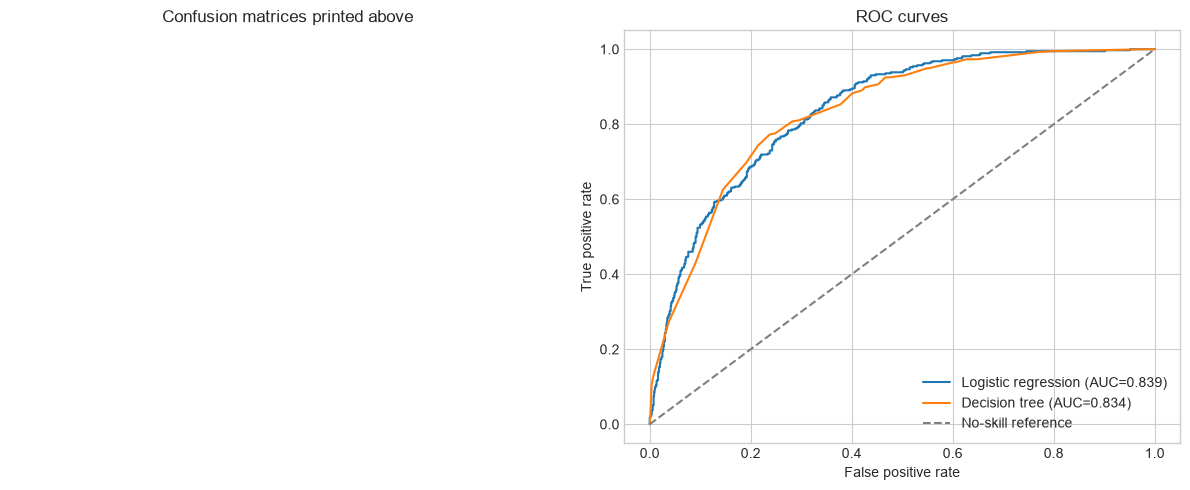

Largest logistic-regression coefficients by absolute magnitude:


,coefficient
categorical__contract_Two year,-0.758
numeric__tenure,-0.755
categorical__internet_service_Fiber optic,0.734
categorical__contract_Month-to-month,0.661
categorical__internet_service_DSL,-0.632
numeric__monthly_charges,-0.561
categorical__streaming_movies_Yes,0.296
categorical__streaming_tv_Yes,0.285
categorical__online_security_No internet service,-0.270
categorical__internet_service_No,-0.270


Largest decision-tree feature importances:


,importance
categorical__contract_Month-to-month,0.6146
numeric__tenure,0.1281
categorical__internet_service_Fiber optic,0.1091
numeric__monthly_charges,0.0532
categorical__contract_Two year,0.0230
categorical__tech_support_No,0.0196
categorical__online_security_No,0.0128
categorical__phone_service_Yes,0.0117
categorical__payment_method_Electronic check,0.0110
categorical__dependents_Yes,0.0056


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for model_name, model_pipeline in classification_pipelines.items():
    predicted = model_pipeline.predict(X_test)
    matrix = confusion_matrix(y_test, predicted, labels=[0, 1])
    axes[0].plot([], [], label=model_name)
    print(f'\n{model_name} confusion matrix (rows=true, columns=predicted; labels No, Yes):\n{matrix}')
    probability = model_pipeline.predict_proba(X_test)[:, 1]
    false_positive_rate, true_positive_rate, _ = roc_curve(y_test, probability)
    auc_value = roc_auc_score(y_test, probability)
    axes[1].plot(false_positive_rate, true_positive_rate, label=f'{model_name} (AUC={auc_value:.3f})')

axes[0].axis('off')
axes[0].set_title('Confusion matrices printed above')
axes[1].plot([0, 1], [0, 1], linestyle='--', color='gray', label='No-skill reference')
axes[1].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC curves')
axes[1].legend()
plt.tight_layout()
plt.show()

feature_names = classification_pipelines['Logistic regression'].named_steps['preprocess'].get_feature_names_out()
logistic_coefficients = classification_pipelines['Logistic regression'].named_steps['classifier'].coef_[0]
logistic_importance = pd.Series(logistic_coefficients, index=feature_names, name='coefficient')
print('Largest logistic-regression coefficients by absolute magnitude:')
display(logistic_importance.reindex(logistic_importance.abs().sort_values(ascending=False).head(15).index).to_frame().round(3))

tree_importance = pd.Series(
    classification_pipelines['Decision tree'].named_steps['classifier'].feature_importances_,
    index=feature_names, name='importance',
).sort_values(ascending=False)
print('Largest decision-tree feature importances:')
display(tree_importance.head(15).to_frame().round(4))

### Linear regression example: predict monthly charges

This separate regression example predicts a numeric outcome using tenure and service/contract descriptors. The monthly-charge target and `total_charges` are excluded from the predictors to avoid direct target leakage. Metrics are evaluated on a held-out test set.

,held-out test performance
R_squared,0.919
MAE,7.143
RMSE,8.543


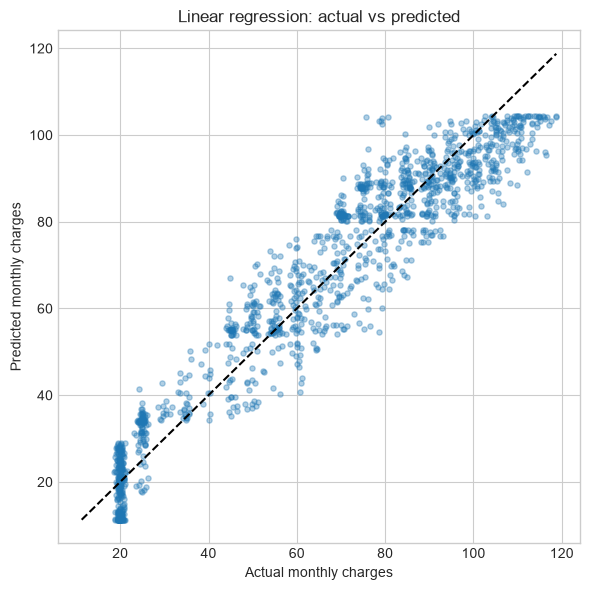

Consolidated measured findings (sample/holdout only):
- Contract with highest observed churn: Month-to-month (42.7%); contract/churn chi-square p=5.863e-258.
- Highest-churn segment: 1 (31.6% churn; 4,659 customers).
- Highest-recall classifier on the stratified test split: Decision tree (recall=0.775, precision=0.530).
- Monthly-charge regression held-out R^2=0.919, MAE=$7.14, RMSE=$8.54.
- Lowest-MAPE temperature forecast: SARIMA(1,1,1)x(1,1,1,12) (MAPE=4.26%). This is not a telecom forecast.
Business implication: test retention outreach on appropriately selected customer groups and weigh missed churn against unnecessary contacts; no observational result here proves that an intervention works.


In [15]:
regression_features = ['tenure', 'contract', 'internet_service', 'phone_service', 'multiple_lines', 'paperless_billing']
regression_numeric = ['tenure']
regression_categorical = [column for column in regression_features if column not in regression_numeric]
X_regression = telco[regression_features]
y_regression = telco['monthly_charges']
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_regression, y_regression, test_size=0.2, random_state=SEED,
)
regression_preprocessor = ColumnTransformer([
    ('numeric', StandardScaler(), regression_numeric),
    ('categorical', OneHotEncoder(handle_unknown='ignore'), regression_categorical),
])
linear_model = Pipeline([
    ('preprocess', regression_preprocessor),
    ('regressor', LinearRegression()),
])
linear_model.fit(X_reg_train, y_reg_train)
regression_prediction = linear_model.predict(X_reg_test)
regression_results = pd.Series({
    'R_squared': linear_model.score(X_reg_test, y_reg_test),
    'MAE': mean_absolute_error(y_reg_test, regression_prediction),
    'RMSE': np.sqrt(mean_squared_error(y_reg_test, regression_prediction)),
}, name='held-out test performance')
display(regression_results.to_frame().round(3))

plt.figure(figsize=(6, 6))
plt.scatter(y_reg_test, regression_prediction, alpha=0.35, s=14)
limits = [min(y_reg_test.min(), regression_prediction.min()), max(y_reg_test.max(), regression_prediction.max())]
plt.plot(limits, limits, linestyle='--', color='black')
plt.xlabel('Actual monthly charges')
plt.ylabel('Predicted monthly charges')
plt.title('Linear regression: actual vs predicted')
plt.tight_layout()
plt.show()

best_recall_model = classification_results['recall'].idxmax()
best_weather_model = forecast_results['MAPE_percent'].idxmin()
highest_churn_segment = segment_profile['churn_rate'].idxmax()
print('Consolidated measured findings (sample/holdout only):')
print(f'- Contract with highest observed churn: {highest_churn_contract} ({contract_churn_rates.max():.1%}); contract/churn chi-square p={chi2_p:.3e}.')
print(f'- Highest-churn segment: {highest_churn_segment} ({segment_profile.loc[highest_churn_segment, "churn_rate"]:.1%} churn; {int(segment_profile.loc[highest_churn_segment, "customer_count"]):,} customers).')
print(f'- Highest-recall classifier on the stratified test split: {best_recall_model} (recall={classification_results.loc[best_recall_model, "recall"]:.3f}, precision={classification_results.loc[best_recall_model, "precision"]:.3f}).')
print(f'- Monthly-charge regression held-out R^2={regression_results["R_squared"]:.3f}, MAE=${regression_results["MAE"]:.2f}, RMSE=${regression_results["RMSE"]:.2f}.')
print(f'- Lowest-MAPE temperature forecast: {best_weather_model} (MAPE={forecast_results.loc[best_weather_model, "MAPE_percent"]:.2f}%). This is not a telecom forecast.')
print('Business implication: test retention outreach on appropriately selected customer groups and weigh missed churn against unnecessary contacts; no observational result here proves that an intervention works.')

## 6. Findings, business implications, and limitations

The code cell above summarizes measured results from the sample and held-out splits. Review the confidence intervals, effect sizes, cluster profiles, confusion matrices, and regression/forecast error tables before turning them into a business recommendation. In particular, choose a churn decision threshold based on the relative cost of missed churn and unnecessary outreach; the default 0.5 threshold is only a comparison baseline.


The Telco file is a fictional, cross-sectional sample with no dates, customer history, or intervention data. `tenure` and `total_charges` are strongly correlated; total charges are omitted from the churn model because their timing may overlap the outcome. Group differences, correlations, cluster patterns, and model feature importance are not causal explanations. One train/test split does not quantify uncertainty across future samples; before deployment, use cross-validation, calibration and threshold analysis, temporal/customer-level validation where appropriate, fairness review, and a controlled business test. Do not claim a forecast or model accuracy unless it is computed above on the stated held-out data.